# IMDB Sentiment Analysis – Naive Bayes

**Goal:** Classify movie reviews as **positive or negative**.

**Dataset:** `IMDB Dataset.csv` – 50,000 reviews (download link in `data/README.md`)

**Approach:** Remove duplicates → text cleaning (HTML tags, punctuation, lowercase) → TF-IDF (2,000 features, English stop words) → Naive Bayes → accuracy, confusion matrix, classification report, plus a helper to predict the sentiment of new text.

## Load the data

In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
df=pd.read_csv("../data/IMDB Dataset.csv")
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


In [2]:
df.columns

Index(['review', 'sentiment'], dtype='object')

In [3]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
df.tail()

,review,sentiment
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative
49999,No one expects the Star Trek movies to be high...,negative


## Exploratory data analysis

In [5]:
df.describe()

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


In [6]:
df.describe(include="O")

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


In [7]:
df.duplicated().sum()

np.int64(418)

## Data cleaning & preprocessing

In [8]:
df=df.drop_duplicates()

In [9]:
df.isna().sum().sort_values(ascending=False)

review       0
sentiment    0
dtype: int64

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49582 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     49582 non-null  object
 1   sentiment  49582 non-null  object
dtypes: object(2)
memory usage: 1.1+ MB


In [11]:
df["sentiment"]=df["sentiment"].map({"positive":1,"negative":0})
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1
...,...,...
49995,I thought this movie did a down right good job...,1
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",0
49997,I am a Catholic taught in parochial elementary...,0
49998,I'm going to have to disagree with the previou...,0


In [12]:
import re

def clean_text(text):
    text = re.sub(r'<br\s*/?>', ' ', text) 
    text = re.sub(r'[^a-zA-Z\s]', '', text)  
    text = text.lower()
    return text

df['review_clean'] = df['review'].apply(clean_text)

In [13]:
df

,review,sentiment,review_clean
0,One of the other reviewers has mentioned that ...,1,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,1,a wonderful little production the filming te...
2,I thought this was a wonderful way to spend ti...,1,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,0,basically theres a family where a little boy j...
4,"Petter Mattei's ""Love in the Time of Money"" is...",1,petter matteis love in the time of money is a ...
...,...,...,...
49995,I thought this movie did a down right good job...,1,i thought this movie did a down right good job...
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",0,bad plot bad dialogue bad acting idiotic direc...
49997,I am a Catholic taught in parochial elementary...,0,i am a catholic taught in parochial elementary...
49998,I'm going to have to disagree with the previou...,0,im going to have to disagree with the previous...


## Train / test split

In [14]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(df.review_clean, df.sentiment, train_size=0.8, random_state=42)


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

v = TfidfVectorizer(max_features=2000, stop_words='english')
x_train_count = v.fit_transform(x_train.values)

## Model training

In [16]:
from sklearn.naive_bayes import GaussianNB
gaussian=GaussianNB()
gaussian.fit(x_train_count.toarray(), y_train) 


def predict_sentiment(text):
    text_clean = clean_text(text)
    text_vector = v.transform([text_clean]).toarray()
    prediction = gaussian.predict(text_vector)[0]
    return "Positive" if prediction == 1 else "Negative"


review = "This movie was absolutely amazing, I loved every second of it"
print(predict_sentiment(review))

Positive


## Evaluation

In [17]:
x_test_count = v.transform(x_test.values)
print("Test Model : ", gaussian.score(x_test_count.toarray(), y_test))
print("Train Model :", gaussian.score(x_train_count.toarray(), y_train))

Test Model :  0.8149642028839367


Train Model : 0.8250598764653977


[[4019  920]
 [ 915 4063]]


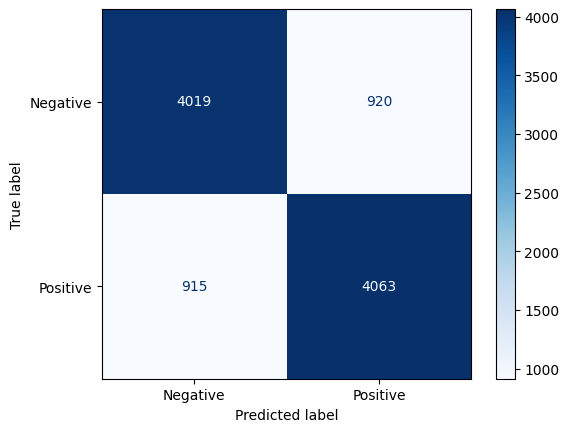

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
y_pred = gaussian.predict(x_test_count.toarray())
cm = confusion_matrix(y_test, y_pred)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
disp.plot(cmap='Blues')
plt.show()

In [19]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

              precision    recall  f1-score   support

    Negative       0.81      0.81      0.81      4939
    Positive       0.82      0.82      0.82      4978

    accuracy                           0.81      9917
   macro avg       0.81      0.81      0.81      9917
weighted avg       0.81      0.81      0.81      9917



## Comparison: Multinomial Naive Bayes

`GaussianNB` assumes every feature is normally distributed, which does not really hold for sparse TF-IDF values. `MultinomialNB` models word frequencies directly and works on the sparse matrix without `.toarray()`.

In [20]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

multinomial = MultinomialNB()
multinomial.fit(x_train_count, y_train)

print("GaussianNB    test accuracy:", accuracy_score(y_test, y_pred))
print("MultinomialNB test accuracy:", accuracy_score(y_test, multinomial.predict(x_test_count)))

GaussianNB    test accuracy:

 0.8149642028839367
MultinomialNB test accuracy: 0.8422910154280528


## Results & conclusion

| Model | Train accuracy | Test accuracy |
|---|---|---|
| GaussianNB | 0.83 | 0.81 |
| **MultinomialNB** | – | **0.84** |

* Both classes are predicted equally well (F1 ≈ 0.81–0.82 for GaussianNB), so the model is not biased towards one sentiment.
* `MultinomialNB` beats `GaussianNB` by ~3 points: it matches the nature of TF-IDF / word-count features and runs on the sparse matrix directly (faster, less memory).
* Further improvements: bigrams (`ngram_range=(1, 2)`), a larger vocabulary than 2,000 features, or a linear model such as Logistic Regression on the same features.